# Adult Income: Random Forest, end to end
## Goal and methodology
Predict income above $50,000 using the actual UCI Adult Census dataset. This portfolio tutorial covers the 17 requested exercises and a separate five-fold model-selection workflow. Results below are computed, never placeholders.

**Source:** Becker & Kohavi (1996), [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult), DOI: 10.24432/C5XW20, CC BY 4.0. Records originate in the 1994 Census database.

### Key assumptions
We pool the two original source files, remove exact duplicate records before splitting, and use a reproducible stratified 80/20 development/test split. The original six features are those in the supplied notebook. Tutorial depth selection uses a validation subset of development data, never the final test set. Five-fold comparisons and random search use development data only. Accuracy is unweighted per record; `fnlwgt` is neither a predictor nor a sample weight. This is a historical benchmark, not a deployable income decision system.

## Executed results
Default original validation accuracy: **81.78%**; depth-tuned original: **83.20%**; depth-tuned education: **84.19%**.
Selected feature group: **Expanded + interaction**; best searched five-fold F1: **0.7004**.
Final held-out test: accuracy **83.22%**, positive-class F1 **0.6990**, ROC-AUC **0.9142**.
All **9 code cells** executed sequentially in a fresh kernel with zero error outputs. Validation scores are model-selection evidence, not test estimates.

At fixed depth 16 under identical five-fold validation, F1 increased from 0.5031 (original) to 0.5787 (education), 0.6689 (expanded), and 0.6760 (expanded plus interaction). The interaction's observed incremental gain is small and has not been tested for statistical significance.

Tuning trades accuracy for positive-class recovery: under the same folds, the selected candidate has accuracy **83.40%**, recall **81.03%** and F1 **0.7004**, compared with **86.05%**, **60.78%** and **0.6760** for its fixed-parameter feature-comparison model. This is consistent with the stated F1 objective.


## Setup
Use the project `.venv312` interpreter (Python 3.12) and install `requirements.txt`. This cell records the executable and package versions actually used. The original notebook specified generic `python3`; a running IDE kernel cannot be inferred from that metadata. Downloads are cached under `data/`, with SHA-256 provenance recorded.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, platform, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, ucimlrepo, ipykernel
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
SEED = 42
JOBS = min(4, os.cpu_count() or 1)
N_ITER = 12  # bounded search: 60 fits; increase for a more exhaustive study
np.random.seed(SEED)
OUT = Path('artifacts'); OUT.mkdir(exist_ok=True)
versions = {p: metadata.version(p) for p in ['pandas','numpy','matplotlib','seaborn','scikit-learn','ucimlrepo','scipy','ipykernel','nbclient','nbformat']}
print('Python:', sys.executable, platform.python_version(), 'forest threads:', JOBS)
display(pd.Series(versions, name='version'))
sns.set_theme(style='whitegrid', palette=['#245782','#C17C28'])
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})
def savefig(name):
    plt.tight_layout(); plt.savefig(OUT / (name + '.png'), bbox_inches='tight'); plt.show()


Matplotlib is building the font cache; this may take a moment.


Python: [LOCAL_WORKSPACE]\.venv312\Scripts\python.exe 3.12.14 forest threads: 4


pandas           3.0.6
numpy            2.5.4
matplotlib      3.11.2
seaborn         0.13.2
scikit-learn     1.9.1
ucimlrepo        0.0.7
scipy           1.18.1
ipykernel        7.4.0
nbclient        0.11.0
nbformat        5.11.1
Name: version, dtype: str

## Data verification and cleaning — tasks 1–4
Whitespace and terminal target punctuation are deterministic record-level cleaning. Missing `?` values become nulls. We retain missing predictors for fold-local imputation. Exact full-record duplicates are removed conservatively; legitimate identical individuals cannot be distinguished without identifiers.

Raw source shape: (48842, 15)


Exact duplicate records removed: 52


,dtype,missing,unique
age,int64,0,74
workclass,str,2799,8
fnlwgt,int64,0,28523
education,str,0,16
education-num,int64,0,16
marital-status,str,0,7
occupation,str,2809,14
relationship,str,0,6
race,str,0,5
sex,str,0,2


,workclass,education,marital-status,occupation,relationship,race,sex,native-country,income
0,Federal-gov,10th,Divorced,Adm-clerical,Husband,Amer-Indian-Eskimo,Female,Cambodia,<=50K
1,Local-gov,11th,Married-AF-spouse,Armed-Forces,Not-in-family,Asian-Pac-Islander,Male,Canada,>50K
2,Never-worked,12th,Married-civ-spouse,Craft-repair,Other-relative,Black,NaN,China,NaN
3,Private,1st-4th,Married-spouse-absent,Exec-managerial,Own-child,Other,NaN,Columbia,NaN
4,Self-emp-inc,5th-6th,Never-married,Farming-fishing,Unmarried,White,NaN,Cuba,NaN
5,Self-emp-not-inc,7th-8th,Separated,Handlers-cleaners,Wife,NaN,NaN,Dominican-Republic,NaN
6,State-gov,9th,Widowed,Machine-op-inspct,NaN,NaN,NaN,Ecuador,NaN
7,Without-pay,Assoc-acdm,NaN,Other-service,NaN,NaN,NaN,El-Salvador,NaN
8,NaN,Assoc-voc,NaN,Priv-house-serv,NaN,NaN,NaN,England,NaN
9,NaN,Bachelors,NaN,Prof-specialty,NaN,NaN,NaN,France,NaN


,count,percent
income,,
<=50K,37109,76.058619
>50K,11681,23.941381


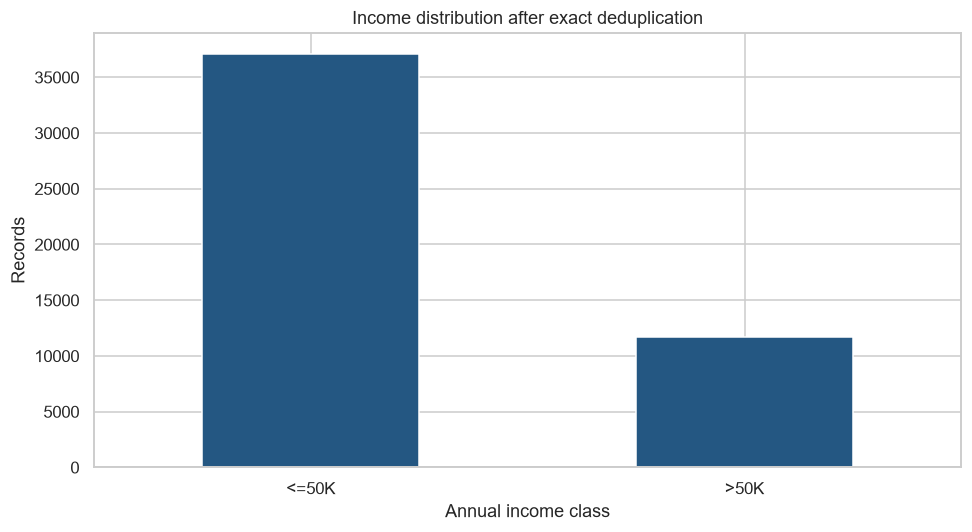

388

In [2]:
import urllib.request
columns = ['age','workclass','fnlwgt','education','education-num','marital-status','occupation',
           'relationship','race','sex','capital-gain','capital-loss','hours-per-week','native-country','income']
DATA = Path('data'); DATA.mkdir(exist_ok=True)
base = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/'
frames, provenance = [], {}
for filename, skip in [('adult.data',0), ('adult.test',1)]:
    local = DATA / filename
    if not local.exists():
        urllib.request.urlretrieve(base + filename, local)
    provenance[filename] = {'url': base + filename, 'sha256': hashlib.sha256(local.read_bytes()).hexdigest()}
    frames.append(pd.read_csv(local, names=columns, header=None, skiprows=skip))
raw = pd.concat(frames, ignore_index=True)
assert raw.shape == (48842, 15), raw.shape
print('Raw source shape:', raw.shape)
df = raw.copy()
for col in df.select_dtypes(include=['object','string']).columns:
    df[col] = df[col].str.strip().replace('?', np.nan)
df['income'] = df['income'].str.rstrip('.')
assert set(df.income.unique()) == {'<=50K','>50K'}
assert df.income.notna().all()
duplicate_count = int(df.duplicated().sum())
print('Exact duplicate records removed:', duplicate_count)
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'unique': df.nunique()}))
display(pd.DataFrame({c: pd.Series(sorted(df[c].dropna().unique())) for c in df.select_dtypes(include=['object','string']).columns}))
df = df.drop_duplicates().reset_index(drop=True)
distribution = df.income.value_counts().rename_axis('income').to_frame('count')
distribution['percent'] = 100 * distribution['count'] / len(df)
display(distribution)
distribution['count'].plot.bar(rot=0, color='#245782')
plt.title('Income distribution after exact deduplication'); plt.ylabel('Records'); plt.xlabel('Annual income class')
savefig('income_distribution')
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2))


## Leakage-safe split and features — task 5
All learned imputation and encoding live inside pipelines. Education bins use fixed cut points: 1–9 (high school or less), 10–13 (some college through bachelors), 14–16 (postgraduate). Expanded features retain the education group and add workclass, occupation, marital status, relationship and country. The age × weekly-hours interaction is a hypothesis, not measured annual work. Expanded features omit sex/race, but proxies remain; this is not a fairness guarantee. An expanded ablation without the interaction tests its value. Education number/text are omitted to avoid redundant encodings.

In [3]:
df['education_bin'] = pd.cut(df['education-num'], [0,9,13,16], labels=['HS or less','College to Bachelors','Postgraduate']).astype(object)
assert df.education_bin.notna().all()
df['hours_age_interaction'] = df['age'] * df['hours-per-week']
y = df.income.eq('>50K').astype(int)
original = ['age','capital-gain','capital-loss','hours-per-week','sex','race']
education = original + ['education_bin']
expanded = ['age','capital-gain','capital-loss','hours-per-week','education_bin','workclass',
            'occupation','marital-status','relationship','native-country']
feature_sets = {'Original six': original, 'Plus education': education,
                'Expanded census': expanded, 'Expanded + interaction': expanded + ['hours_age_interaction']}
all_cols = sorted(set(sum(feature_sets.values(), [])))
X = df[all_cols]
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=.25, stratify=y_dev, random_state=SEED)
assert set(X_dev.index).isdisjoint(X_test.index)
assert set(X_train.index).isdisjoint(X_val.index)
print('Training, validation, final test:', len(X_train), len(X_val), len(X_test))
print('Positive proportions:', y_train.mean(), y_val.mean(), y_test.mean())
def make_pipeline(cols, **params):
    categorical = [c for c in cols if not pd.api.types.is_numeric_dtype(X[c])]
    numerical = [c for c in cols if c not in categorical]
    pre = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), numerical),
        ('categorical', Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
            ('encode',OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical)])
    return Pipeline([('preprocess',pre), ('forest',RandomForestClassifier(random_state=SEED,n_jobs=JOBS,**params))])
def importance(model):
    return pd.DataFrame({'feature': model['preprocess'].get_feature_names_out(),
                         'importance': model['forest'].feature_importances_}).sort_values('importance',ascending=False)


Training, validation, final test: 29274 9758 9758
Positive proportions: 0.23942747830839653 0.23939331830293092 0.23939331830293092


## Tutorial experiments — tasks 6–17
Fit the default 100-tree baseline, tune depths 1–25 on validation accuracy, then repeat with education categories. Ties choose the shallowest depth. Training curves diagnose fit; high training accuracy alone is insufficient. This preserves the supplied exercises while replacing their repeated test-set selection with validation. Results are not claimed to reproduce a separately supplied Codecademy answer key.

Default Random Forest validation accuracy: 0.8177905308464849
Majority-class validation accuracy: 0.760606681697069


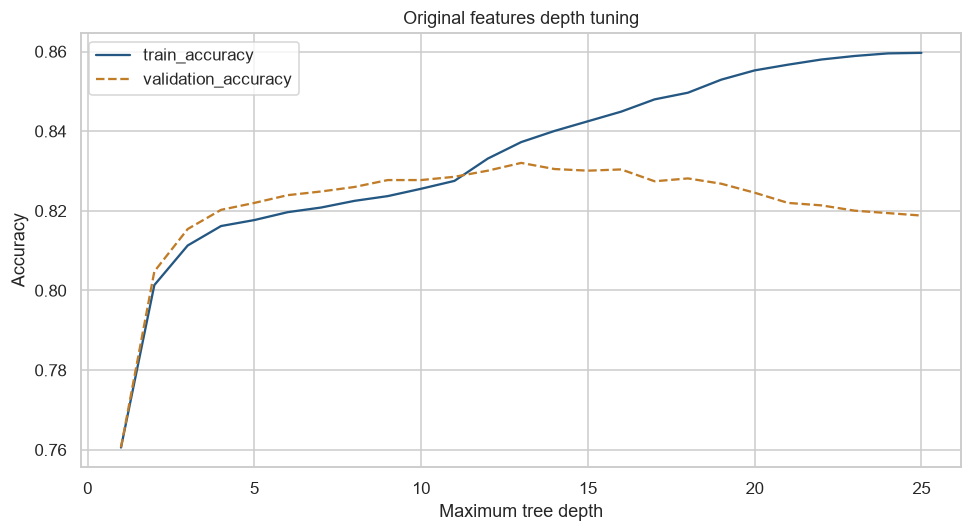

Original features depth tuning {'depth': 13.0, 'train_accuracy': 0.8372617339618774, 'validation_accuracy': 0.8320352531256405}


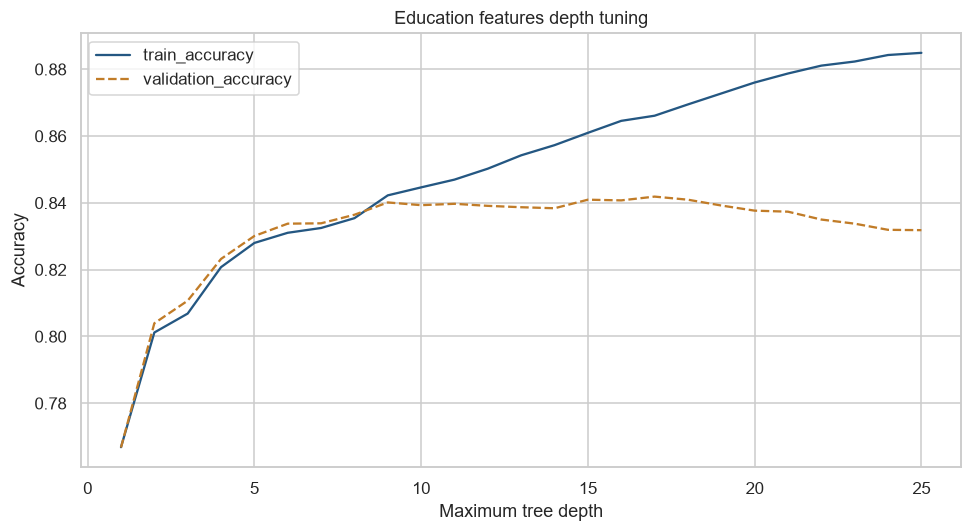

Education features depth tuning {'depth': 17.0, 'train_accuracy': 0.8660927785748446, 'validation_accuracy': 0.8418733346997336}


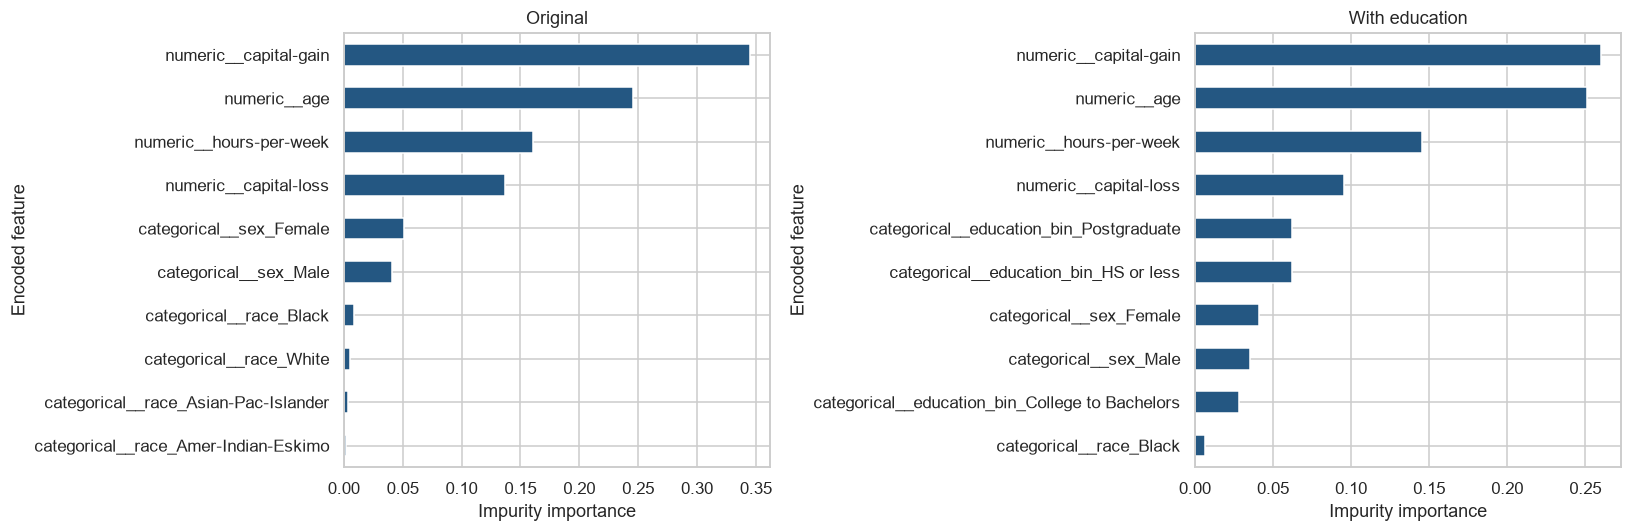

,model,validation_accuracy
0,Default original,0.817791
1,Depth-tuned original,0.832035
2,Depth-tuned education,0.841873


Education changes best validation accuracy by **+0.98 percentage points**. This comparison includes depth selection and is exploratory.

In [4]:
baseline = make_pipeline(original)
baseline.fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_val, baseline.predict(X_val))
print('Default Random Forest validation accuracy:', baseline_accuracy)
print('Majority-class validation accuracy:', accuracy_score(y_val, np.repeat(y_train.mode()[0],len(y_val))))
def depth_experiment(cols, title):
    rows = []
    for depth in range(1,26):
        model = make_pipeline(cols,max_depth=depth)
        model.fit(X_train,y_train)
        rows.append({'depth':depth,'train_accuracy':accuracy_score(y_train,model.predict(X_train)),
                     'validation_accuracy':accuracy_score(y_val,model.predict(X_val))})
    table = pd.DataFrame(rows)
    best = table.loc[table.validation_accuracy.idxmax()]
    selected = make_pipeline(cols,max_depth=int(best.depth)).fit(X_train,y_train)
    ax = table.plot(x='depth',y=['train_accuracy','validation_accuracy'],style=['-','--'])
    ax.set(xlabel='Maximum tree depth',ylabel='Accuracy',title=title)
    savefig(title.replace(' ','_'))
    print(title, best.to_dict())
    return table, best, selected
original_curve, original_best, original_model = depth_experiment(original,'Original features depth tuning')
education_curve, education_best, education_model = depth_experiment(education,'Education features depth tuning')
imp_comparison = pd.concat([importance(original_model).assign(model='Original'),importance(education_model).assign(model='Education')])
fig, axes = plt.subplots(1,2,figsize=(15,5))
for ax, model, title in zip(axes,[original_model,education_model],['Original','With education']):
    importance(model).head(10).sort_values('importance').plot.barh(x='feature',y='importance',ax=ax,legend=False)
    ax.set(title=title,xlabel='Impurity importance',ylabel='Encoded feature')
savefig('tutorial_importance_comparison')
display(pd.DataFrame({'model':['Default original','Depth-tuned original','Depth-tuned education'],
    'validation_accuracy':[baseline_accuracy,original_best.validation_accuracy,education_best.validation_accuracy]}))
display(Markdown(f'Education changes best validation accuracy by **{100*(education_best.validation_accuracy-original_best.validation_accuracy):+.2f} percentage points**. This comparison includes depth selection and is exploratory.'))


## Five-fold feature comparison
The same shuffled stratified folds and fixed 100-tree, depth-16 forest compare all candidate groups. Report all five metrics and F1 dispersion; fold standard deviations are descriptive, not confidence intervals. Select the feature group by mean positive-class F1. These folds remain internal development evidence; selection can make their scores optimistic.

Cross-validating Original six


Cross-validating Plus education


Cross-validating Expanded census


Cross-validating Expanded + interaction


,model,accuracy,precision,recall,f1,roc_auc,f1_std,train_f1
3,Expanded + interaction,0.8605,0.7615,0.6078,0.6760,0.9136,0.0085,0.7509
2,Expanded census,0.8594,0.7669,0.5934,0.6689,0.9129,0.0131,0.7374
1,Plus education,0.8383,0.7686,0.4643,0.5787,0.8681,0.0168,0.6491
0,Original six,0.8266,0.8010,0.3668,0.5031,0.8478,0.0080,0.5620


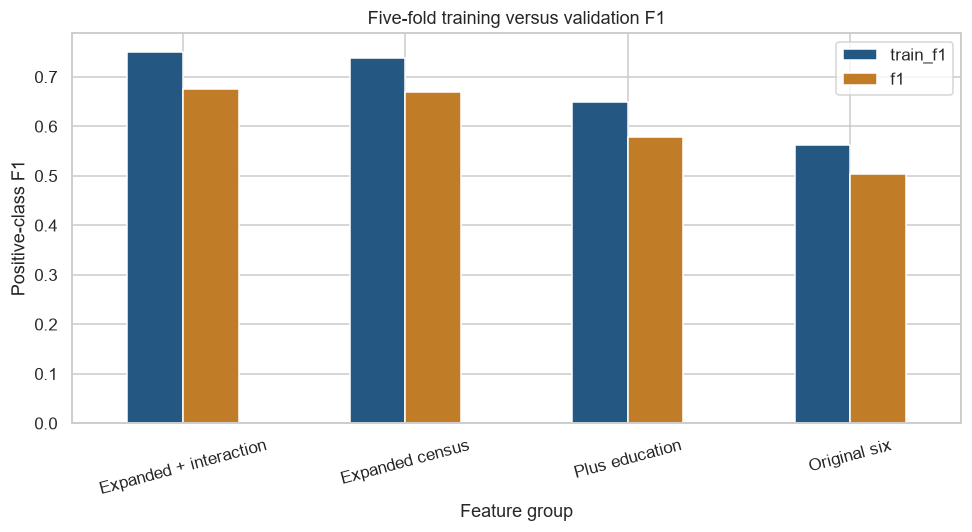

Selected feature group: Expanded + interaction


In [5]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
scoring = {'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','roc_auc':'roc_auc'}
rows = []
fold_rows = []
for name, cols in feature_sets.items():
    print('Cross-validating',name,flush=True)
    result = cross_validate(make_pipeline(cols,n_estimators=100,max_depth=16),X_dev,y_dev,cv=cv,
        scoring=scoring,n_jobs=1,return_train_score=True,error_score='raise')
    rows.append({'model':name,**{m:result['test_'+m].mean() for m in scoring},
                 'f1_std':result['test_f1'].std(ddof=1),'train_f1':result['train_f1'].mean()})
    fold_rows.extend([{'model':name,'fold':i+1,**{m:result['test_'+m][i] for m in scoring}} for i in range(5)])
comparison = pd.DataFrame(rows).sort_values('f1',ascending=False)
display(comparison.round(4))
winning_name = comparison.iloc[0]['model']; winning_cols = feature_sets[winning_name]
comparison.to_csv(OUT/'feature_comparison.csv',index=False)
pd.DataFrame(fold_rows).to_csv(OUT/'feature_comparison_folds.csv',index=False)
comparison.set_index('model')[['train_f1','f1']].plot.bar(rot=15)
plt.ylabel('Positive-class F1'); plt.xlabel('Feature group'); plt.title('Five-fold training versus validation F1')
savefig('cv_feature_comparison')
print('Selected feature group:',winning_name)


## Hyperparameter optimisation
RandomizedSearchCV evaluates 12 reproducible combinations × five folds, using positive-class F1 for refitting while recording accuracy, precision, recall and ROC-AUC. Forests use at most four threads; search runs sequentially to avoid nested CPU oversubscription. The 12-trial budget is an explicit computational compromise and is not a claim of global optimality. The final threshold stays at 0.5.

Fitting 5 folds for each of 12 candidates, totalling 60 fits


Best CV F1: 0.7004175050400279
Best parameters: {'forest__n_estimators': 100, 'forest__min_samples_split': 10, 'forest__min_samples_leaf': 1, 'forest__max_features': 1.0, 'forest__max_depth': 20, 'forest__class_weight': 'balanced_subsample'}


,params,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_roc_auc
11,"{'forest__n_estimators': 100, 'forest__min_sam...",0.834034,0.616803,0.810273,0.700418,0.912407
1,"{'forest__n_estimators': 200, 'forest__min_sam...",0.829909,0.607346,0.819583,0.697661,0.913496
9,"{'forest__n_estimators': 300, 'forest__min_sam...",0.815177,0.577341,0.851043,0.687968,0.914254
2,"{'forest__n_estimators': 300, 'forest__min_sam...",0.812974,0.572866,0.860353,0.687765,0.914338
3,"{'forest__n_estimators': 200, 'forest__min_sam...",0.810796,0.569672,0.857892,0.684680,0.913676


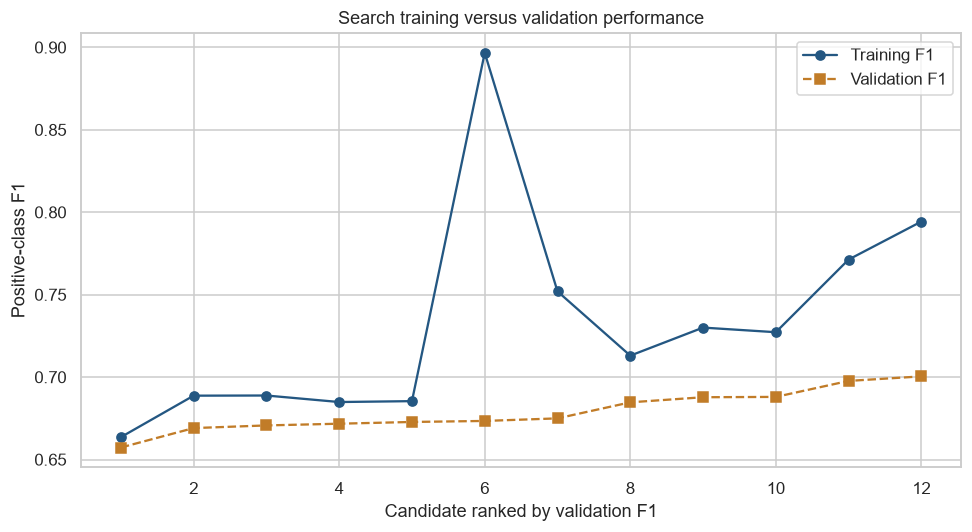

In [6]:
search = RandomizedSearchCV(make_pipeline(winning_cols),param_distributions={
    'forest__n_estimators':[100,200,300], 'forest__max_depth':[8,12,16,20,None],
    'forest__max_features':['sqrt',.5,1.0], 'forest__min_samples_split':[2,5,10],
    'forest__min_samples_leaf':[1,2,4,8], 'forest__class_weight':[None,'balanced','balanced_subsample']},
    n_iter=N_ITER,scoring=scoring,refit='f1',cv=cv,random_state=SEED,n_jobs=1,
    verbose=1,return_train_score=True,error_score='raise')
search.fit(X_dev,y_dev)
best_model = search.best_estimator_
search_results = pd.DataFrame(search.cv_results_)
search_results.to_csv(OUT/'random_search.csv',index=False)
print('Best CV F1:',search.best_score_); print('Best parameters:',search.best_params_)
display(search_results.sort_values('rank_test_f1')[['params']+['mean_test_'+m for m in scoring]].head(5))
plot = search_results.sort_values('mean_test_f1').reset_index(drop=True)
plt.plot(plot.index+1,plot.mean_train_f1,'o-',label='Training F1')
plt.plot(plot.index+1,plot.mean_test_f1,'s--',label='Validation F1')
plt.xlabel('Candidate ranked by validation F1'); plt.ylabel('Positive-class F1'); plt.title('Search training versus validation performance'); plt.legend()
savefig('search_train_validation')


## Final held-out evaluation
This is the only test-set model evaluation. No test score is used to choose features, parameters or thresholds. Training/validation scores above and final test scores below have different roles and denominators.

accuracy     0.832240
precision    0.612633
recall       0.813784
f1           0.699026
roc_auc      0.914180
Name: Held-out test, dtype: float64

               precision    recall  f1-score   support

Income <=$50K       0.93      0.84      0.88      7422
 Income >$50K       0.61      0.81      0.70      2336

     accuracy                           0.83      9758
    macro avg       0.77      0.83      0.79      9758
 weighted avg       0.86      0.83      0.84      9758



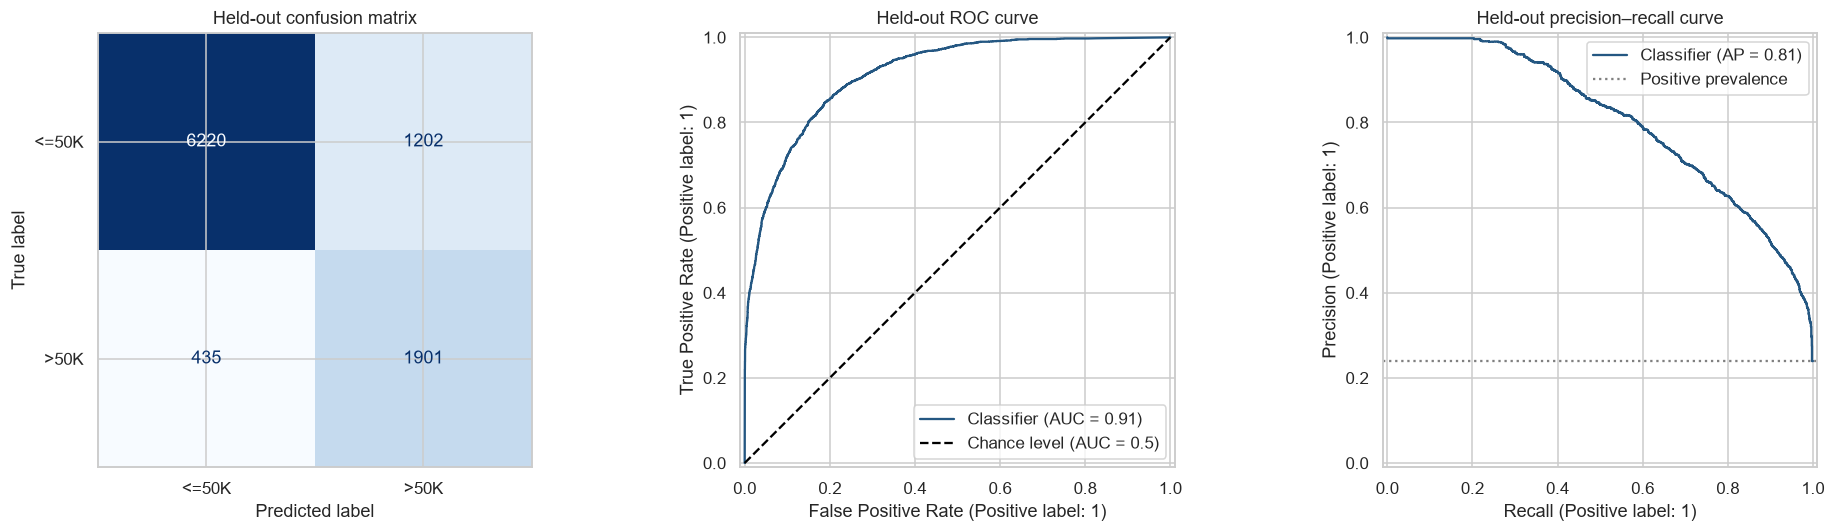

,feature,importance
32,categorical__marital-status_Married-civ-spouse,0.398080
1,numeric__capital-gain,0.125868
4,numeric__hours_age_interaction,0.119512
6,categorical__education_bin_HS or less,0.076642
0,numeric__age,0.058097
2,numeric__capital-loss,0.037439
3,numeric__hours-per-week,0.030148
7,categorical__education_bin_Postgraduate,0.016655
19,categorical__occupation_Exec-managerial,0.010126
23,categorical__occupation_Other-service,0.008817


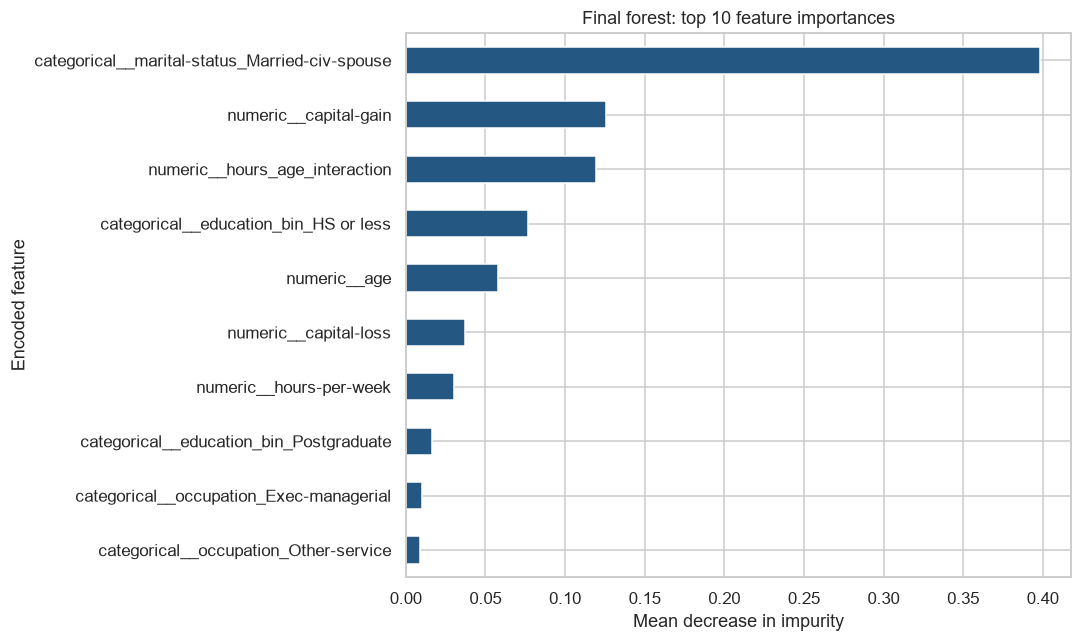

In [7]:
final_pred = best_model.predict(X_test)
final_probability = best_model.predict_proba(X_test)[:,1]
final_metrics = {'accuracy':accuracy_score(y_test,final_pred),
    'precision':precision_score(y_test,final_pred,zero_division=0),
    'recall':recall_score(y_test,final_pred,zero_division=0),
    'f1':f1_score(y_test,final_pred,zero_division=0),'roc_auc':roc_auc_score(y_test,final_probability)}
display(pd.Series(final_metrics,name='Held-out test'))
print(classification_report(y_test,final_pred,target_names=['Income <=$50K','Income >$50K'],zero_division=0))
fig, axes = plt.subplots(1,3,figsize=(18,5))
ConfusionMatrixDisplay.from_predictions(y_test,final_pred,display_labels=['<=50K','>50K'],ax=axes[0],colorbar=False,cmap='Blues')
axes[0].set_title('Held-out confusion matrix')
RocCurveDisplay.from_predictions(y_test,final_probability,ax=axes[1],plot_chance_level=True)
axes[1].set_title('Held-out ROC curve')
PrecisionRecallDisplay.from_predictions(y_test,final_probability,ax=axes[2])
axes[2].axhline(y_test.mean(),linestyle=':',color='grey',label='Positive prevalence'); axes[2].legend()
axes[2].set_title('Held-out precision–recall curve')
savefig('final_evaluation')
importance_df = importance(best_model)
display(importance_df.head(10))
importance_df.head(10).sort_values('importance').plot.barh(x='feature',y='importance',legend=False,figsize=(10,6))
plt.xlabel('Mean decrease in impurity'); plt.ylabel('Encoded feature'); plt.title('Final forest: top 10 feature importances')
savefig('final_importance')
importance_df.to_csv(OUT/'feature_importance.csv',index=False)


## Technical validation
Assertions verify split integrity, raw-record separation, metric arithmetic, target mapping and prediction on missing values and unseen categories. The unseen-observation smoke test exercises the fitted preprocessing without fitting anything on the test set.

In [8]:
assert y.equals(df.income.map({'<=50K':0,'>50K':1}))
assert len(set(X_dev.index) & set(X_test.index)) == 0
record_hash = pd.util.hash_pandas_object(df[columns],index=False)
assert set(record_hash.loc[X_dev.index]).isdisjoint(record_hash.loc[X_test.index])
tn, fp, fn, tp = confusion_matrix(y_test,final_pred).ravel()
assert np.isclose(final_metrics['accuracy'],(tn+tp)/(tn+fp+fn+tp))
assert np.isclose(final_metrics['f1'],2*tp/(2*tp+fp+fn))
assert np.isclose(final_metrics['precision'],tp/(tp+fp))
assert np.isclose(final_metrics['recall'],tp/(tp+fn))
unseen = X_dev.iloc[:2].copy()
for c in winning_cols:
    if pd.api.types.is_numeric_dtype(unseen[c]): unseen.loc[unseen.index[0],c] = np.nan
    else:
        unseen[c] = unseen[c].astype(object)
        unseen.loc[unseen.index[0],c] = 'UNSEEN_CATEGORY'
        unseen.loc[unseen.index[1],c] = np.nan
assert np.isfinite(best_model.predict_proba(unseen)).all()
assert all(0 <= v <= 1 for v in final_metrics.values())
print('All split, target, metric and unseen-observation checks passed.')
results = {'baseline_validation_accuracy':baseline_accuracy,
    'best_original_validation_accuracy':float(original_best.validation_accuracy),
    'best_education_validation_accuracy':float(education_best.validation_accuracy),
    'original_best_depth':int(original_best.depth),'education_best_depth':int(education_best.depth),
    'best_cv_f1':search.best_score_,'selected_features':winning_name,'best_parameters':search.best_params_,
    'test_metrics':final_metrics,'top_five_features':importance_df.head(5).to_dict('records'),
    'raw_shape':list(raw.shape),'clean_shape':list(df.shape),'duplicates_removed':duplicate_count,
    'split_sizes':{'development':len(X_dev),'test':len(X_test)},'versions':versions,
    'python':sys.executable,'seed':SEED,'search_iterations':N_ITER}
(OUT/'results.json').write_text(json.dumps(results,indent=2))


All split, target, metric and unseen-observation checks passed.


1888

## Findings, limitations and recommendations
Impurity feature importances describe this fitted model; they do not establish causation. Continuous and high-cardinality features can receive inflated importance, while correlated predictors split importance. Education and marital/relationship fields may encode structural inequality. Sex and race appear in tutorial models; omitting them in expanded models does not remove demographic proxies. A subgroup error audit, uncertainty estimates and a defensible use case are necessary before any consequential use.

The majority class makes accuracy alone misleading; positive-class F1, precision, recall, ROC and precision–recall provide complementary evidence. Shallow-depth curves reveal underfitting and training–validation gaps reveal overfitting. Fold-local preprocessing prevents learned-transform leakage. Deduplication prevents exact full records crossing partitions, but no person identifier exists to rule out all related observations. The pooled random split differs from the original UCI split and contemporary deployment distributions. No claim of fairness, causality, calibrated probabilities or temporal generalisation is made. Cross-validation selection is not nested and has no unbiased selection-performance guarantee; the untouched test is the final estimate. Follow-up work should compare the original source partition, repeated CV, calibration, subgroup uncertainty and simpler models, using new evaluation data if modelling changes.

In [9]:
delta = float(education_best.validation_accuracy-original_best.validation_accuracy)
cv_index = comparison.set_index('model')
cv_delta = float(cv_index.loc['Plus education','f1']-cv_index.loc['Original six','f1'])
display(Markdown(f"""### Actual conclusions
- Default original validation accuracy: **{baseline_accuracy:.4%}**.
- Best original validation accuracy: **{original_best.validation_accuracy:.4%}** at depth {int(original_best.depth)}.
- Best education validation accuracy: **{education_best.validation_accuracy:.4%}** at depth {int(education_best.depth)}; change **{100*delta:+.3f} percentage points**.
- At consistent depth 16, education changes five-fold F1 by **{cv_delta:+.4f}**; see the feature comparison table for the expanded and interaction ablations. No statistical significance is claimed.
- Selected feature group: **{winning_name}**. Best searched five-fold F1: **{search.best_score_:.4f}**.
- Final test accuracy **{final_metrics['accuracy']:.4%}**, F1 **{final_metrics['f1']:.4f}**, ROC-AUC **{final_metrics['roc_auc']:.4f}**.
- Top encoded predictors: **{', '.join(importance_df.head(5).feature)}**.

All results are from the downloaded UCI records. The twelve-trial search is limited by its budget. Validation gains and impurity rankings should not be interpreted as causal effects or guaranteed deployment improvements."""))


### Actual conclusions
- Default original validation accuracy: **81.7791%**.
- Best original validation accuracy: **83.2035%** at depth 13.
- Best education validation accuracy: **84.1873%** at depth 17; change **+0.984 percentage points**.
- At consistent depth 16, education changes five-fold F1 by **+0.0756**; see the feature comparison table for the expanded and interaction ablations. No statistical significance is claimed.
- Selected feature group: **Expanded + interaction**. Best searched five-fold F1: **0.7004**.
- Final test accuracy **83.2240%**, F1 **0.6990**, ROC-AUC **0.9142**.
- Top encoded predictors: **categorical__marital-status_Married-civ-spouse, numeric__capital-gain, numeric__hours_age_interaction, categorical__education_bin_HS or less, numeric__age**.

All results are from the downloaded UCI records. The twelve-trial search is limited by its budget. Validation gains and impurity rankings should not be interpreted as causal effects or guaranteed deployment improvements.